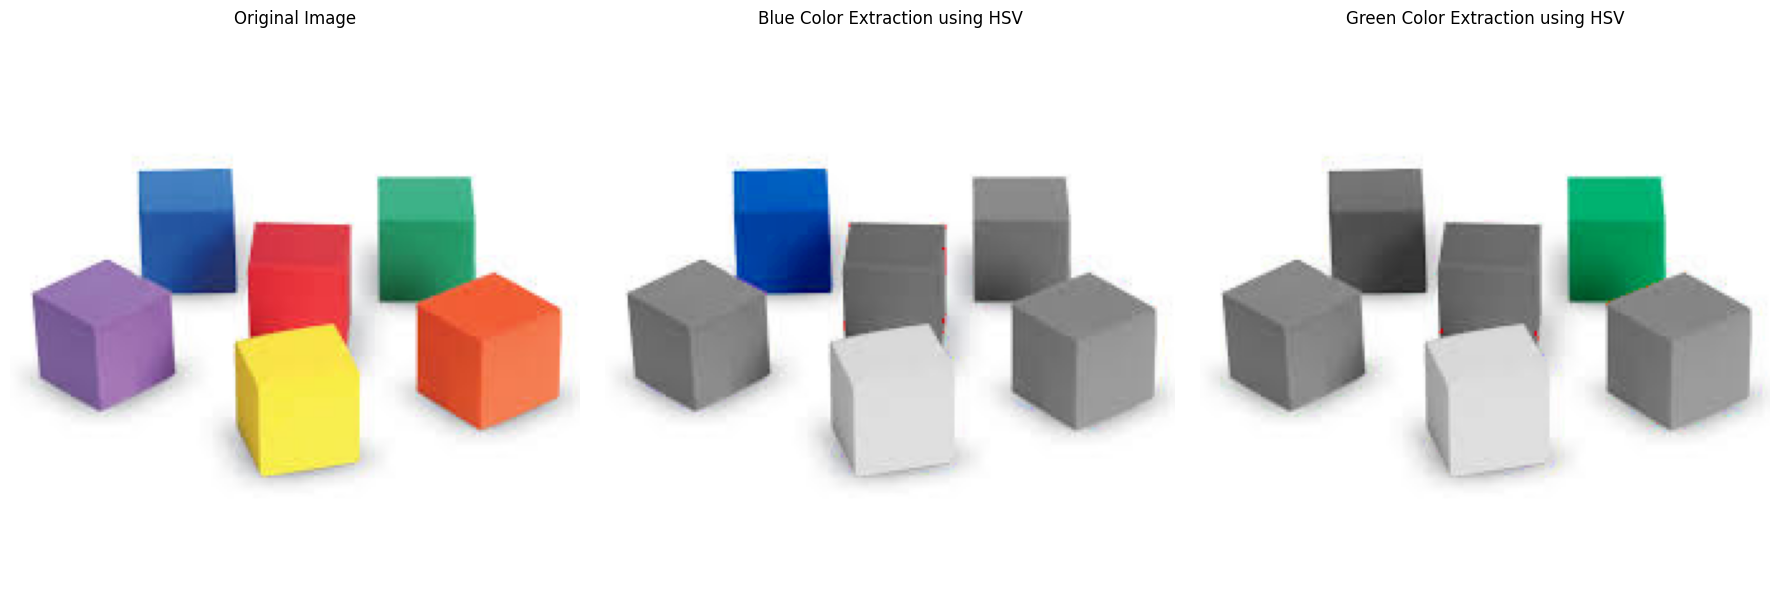

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cubes.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert RGB to HSV
hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

# Apply blur to reduce noise
hsv_blurred = cv2.medianBlur(hsv, 5)

# BLUE SEGMENTATION
lower_blue = np.array([90, 0, 0])
upper_blue = np.array([130, 255, 255])

mask_blue = cv2.inRange(hsv_blurred, lower_blue, upper_blue)

colored_blue = cv2.bitwise_and(image, image, mask=mask_blue)

hsv_blue = cv2.cvtColor(colored_blue, cv2.COLOR_RGB2HSV)
hsv_blue[:,:,1] = np.clip(hsv_blue[:,:,1] * 1.6, 0, 255).astype(np.uint8)
enhanced_blue = cv2.cvtColor(hsv_blue, cv2.COLOR_HSV2RGB)

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
gray = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

inverse_blue = cv2.bitwise_not(mask_blue)
background_blue = cv2.bitwise_and(gray, gray, mask=inverse_blue)
result_blue = cv2.addWeighted(enhanced_blue, 1.0, background_blue, 1.0, 0)

# GREEN SEGMENTATION
lower_green = np.array([35, 0, 0])
upper_green = np.array([85, 255, 255])

mask_green = cv2.inRange(hsv_blurred, lower_green, upper_green)

colored_green = cv2.bitwise_and(image, image, mask=mask_green)

hsv_green = cv2.cvtColor(colored_green, cv2.COLOR_RGB2HSV)
hsv_green[:,:,1] = np.clip(hsv_green[:,:,1] * 1.6, 0, 255).astype(np.uint8)
enhanced_green = cv2.cvtColor(hsv_green, cv2.COLOR_HSV2RGB)

inverse_green = cv2.bitwise_not(mask_green)
background_green = cv2.bitwise_and(gray, gray, mask=inverse_green)
result_green = cv2.addWeighted(enhanced_green, 1.0, background_green, 1.0, 0)

# DISPLAY
plt.figure(figsize=(18, 6))

# Original Image
plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

# Blue Extraction
plt.subplot(1, 3, 2)
plt.imshow(result_blue)
plt.title("Blue Color Extraction using HSV")
plt.axis("off")

# Green Extraction
plt.subplot(1, 3, 3)
plt.imshow(result_green)
plt.title("Green Color Extraction using HSV")
plt.axis("off")

plt.tight_layout()
plt.show()